# 01 Dataset Inspection

This notebook performs a comprehensive, read-only inspection of the BotPrint behavioral dataset.

**Constraints observed:**
- The original Excel file is never modified.
- No values are fabricated.
- No preprocessing or machine learning is performed in this notebook.
- All numerical summaries are saved to `reports/analysis/`.
- All graphs are saved to `reports/figures/`.

In [1]:
# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Resolve project root robustly (kernel cwd is the notebooks/ folder)
_here = Path.cwd()
_root = _here
for _ in range(5):
    if (_root / "README.md").exists():
        break
    _root = _root.parent
PROJECT_ROOT = _root

# Output directories (relative to project root, not kernel cwd)
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
ANALYSIS_DIR = PROJECT_ROOT / "reports" / "analysis"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Figures will be saved to: {FIGURES_DIR}")
print(f"Analysis summaries will be saved to: {ANALYSIS_DIR}")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("\nLibraries imported successfully.")

Project root: C:\My KS\Research\BotPrint-Research
Figures will be saved to: C:\My KS\Research\BotPrint-Research\reports\figures
Analysis summaries will be saved to: C:\My KS\Research\BotPrint-Research\reports\analysis

Libraries imported successfully.


## 2. Load the Excel dataset

The dataset is read from `dataset/raw/BotPrint_Research_Dataset.xlsx` using Pandas. The file is opened in read-only mode; no changes are written back to it.

In [2]:
# 2. Load the Excel dataset
from pathlib import Path

# Resolve project root robustly (kernel cwd is the notebooks/ folder)
_here = Path.cwd()
_root = _here
for _ in range(5):
    if (_root / "README.md").exists():
        break
    _root = _root.parent
PROJECT_ROOT = _root

DATA_PATH = PROJECT_ROOT / "dataset" / "raw" / "BotPrint_Research_Dataset.xlsx"
print(f"Project root: {PROJECT_ROOT}")
print(f"Data path: {DATA_PATH}")
print(f"File exists: {DATA_PATH.exists()}")

xl = pd.ExcelFile(DATA_PATH)
print(f"Sheets in workbook: {xl.sheet_names}")

df = pd.read_excel(DATA_PATH, sheet_name="Events")
print(f"\nLoaded sheet: Events")
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {df.shape[1]}")

Project root: C:\My KS\Research\BotPrint-Research
Data path: C:\My KS\Research\BotPrint-Research\dataset\raw\BotPrint_Research_Dataset.xlsx
File exists: True
Sheets in workbook: ['Events']



Loaded sheet: Events
Number of rows: 1196
Number of columns: 35


## 3. Display the first 10 records

Showing the first 10 rows to understand the structure of individual event records.

In [3]:
# 3. First 10 records
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
display(df.head(10))

,SessionID,UserType,BotType,SessionSource,BotID,CoordinationGroupID,EventType,Timestamp,ElapsedMs,IdleMs,Page,X,Y,DX,DY,Speed,Acceleration,ClickIntervalMs,ClickCount,ScrollDelta,ScrollSpeed,ScrollCount,InterKeyIntervalMs,TypingCount,KeyCategory,FieldType,NavigationCount,SessionDurationMs,TotalMouseSamples,TotalClicks,TotalScrolls,TotalTypingEvents,TotalNavigations,Value,Detail
0,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,click,1792518973669,2,2,/,512.0,514.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,submit,NaN,2,NaN,NaN,NaN,NaN,NaN,BUTTON,NaN
1,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,mousemove,1792518974893,1226,100,/,466.0,369.0,-17.0,-25.0,0.302324,-0.001180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1226,5.0,NaN,NaN,NaN,NaN,NaN,NaN
2,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,mousemove,1792518974577,910,107,/,515.0,490.0,3.0,-23.0,0.216774,0.002026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,910,2.0,NaN,NaN,NaN,NaN,NaN,NaN
3,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,mousemove,1792518975029,1362,136,/,465.0,365.0,-1.0,-4.0,0.030317,-0.002000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1362,6.0,NaN,NaN,NaN,NaN,NaN,NaN
4,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,field_interaction,1792518975733,2066,704,/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,select-one,NaN,2066,NaN,NaN,NaN,NaN,NaN,focusin,NaN
5,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,mousemove,1792518975802,2135,69,/,464.0,363.0,-1.0,-2.0,0.002893,-0.000035,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2135,7.0,NaN,NaN,NaN,NaN,NaN,NaN
6,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Manual,NaN,NaN,mousemove,1792518976367,2700,515,/,464.0,364.0,0.0,1.0,0.001770,-0.000002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2700,8.0,NaN,NaN,NaN,NaN,NaN,NaN
7,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Research participant,NaN,NaN,session_start,1792518978368,0,0,/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,start,NaN
8,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Research participant,NaN,NaN,mousemove,1792518978374,6,3,/,469.0,423.0,0.0,0.0,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,1.0,NaN,NaN,NaN,NaN,NaN,NaN
9,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Human,NaN,Research participant,NaN,NaN,field_interaction,1792518978369,1,1,/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,select-one,NaN,1,NaN,NaN,NaN,NaN,NaN,change,NaN


## 4. Display the last 10 records

Showing the last 10 rows to confirm the tail of the dataset and check for any truncation or anomalies at the end.

In [4]:
# 4. Last 10 records
display(df.tail(10))

,SessionID,UserType,BotType,SessionSource,BotID,CoordinationGroupID,EventType,Timestamp,ElapsedMs,IdleMs,Page,X,Y,DX,DY,Speed,Acceleration,ClickIntervalMs,ClickCount,ScrollDelta,ScrollSpeed,ScrollCount,InterKeyIntervalMs,TypingCount,KeyCategory,FieldType,NavigationCount,SessionDurationMs,TotalMouseSamples,TotalClicks,TotalScrolls,TotalTypingEvents,TotalNavigations,Value,Detail
1186,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162467,31909,101,/,336.0,423.0,-1.0,1.0,0.014002,-0.000037,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31909,163.0,NaN,NaN,NaN,NaN,NaN,NaN
1187,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162005,31447,139,/,318.0,447.0,4.0,0.0,0.028777,-0.006065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31447,160.0,NaN,NaN,NaN,NaN,NaN,NaN
1188,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162366,31808,252,/,337.0,422.0,2.0,-4.0,0.017747,-0.000913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31808,162.0,NaN,NaN,NaN,NaN,NaN,NaN
1189,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162580,32022,113,/,260.0,502.0,-76.0,79.0,0.970107,0.008461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32022,164.0,NaN,NaN,NaN,NaN,NaN,NaN
1190,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162772,32214,192,/,214.0,558.0,-46.0,56.0,0.377451,-0.003087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32214,165.0,NaN,NaN,NaN,NaN,NaN,NaN
1191,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134163082,32524,102,/,145.0,574.0,-7.0,1.0,0.069324,-0.003107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32524,168.0,NaN,NaN,NaN,NaN,NaN,NaN
1192,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162880,32322,108,/,188.0,559.0,-26.0,1.0,0.240919,-0.001264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32322,166.0,NaN,NaN,NaN,NaN,NaN,NaN
1193,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,mousemove,1794134162980,32422,100,/,152.0,573.0,-36.0,14.0,0.386264,0.001453,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32422,167.0,NaN,NaN,NaN,NaN,NaN,NaN
1194,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,session_end,1794134163621,33063,160,/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33063,168.0,19.0,49.0,35.0,2.0,end,NaN
1195,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,NaN,Manual,NaN,NaN,field_interaction,1794134163461,32903,379,/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,submit,NaN,32903,NaN,NaN,NaN,NaN,NaN,focusin,NaN


## 5. Show dataset dimensions

Reporting the total number of rows (events) and columns (features) in the dataset.

In [5]:
# 5. Dataset dimensions
n_rows, n_cols = df.shape
dimensions = pd.DataFrame({
    "metric": ["rows", "columns"],
    "value": [n_rows, n_cols]
})
display(dimensions)
dimensions.to_csv(ANALYSIS_DIR / "dataset_dimensions.csv", index=False)

,metric,value
0,rows,1196
1,columns,35


## 6. Display all column names

Listing every column in the dataset to establish the available features.

In [6]:
# 6. Column names
columns_df = pd.DataFrame({
    "column_index": range(len(df.columns)),
    "column_name": df.columns
})
display(columns_df)
columns_df.to_csv(ANALYSIS_DIR / "column_names.csv", index=False)
print(f"\nTotal columns: {len(df.columns)}")

,column_index,column_name
0,0,SessionID
1,1,UserType
2,2,BotType
3,3,SessionSource
4,4,BotID
5,5,CoordinationGroupID
6,6,EventType
7,7,Timestamp
8,8,ElapsedMs
9,9,IdleMs



Total columns: 35


## 7. Display data types

Showing the data type of each column to distinguish categorical, numeric, and identifier fields.

In [7]:
# 7. Data types
dtypes_df = pd.DataFrame({
    "column_name": df.columns,
    "data_type": df.dtypes.astype(str)
})
display(dtypes_df)
dtypes_df.to_csv(ANALYSIS_DIR / "data_types.csv", index=False)

,column_name,data_type
SessionID,SessionID,str
UserType,UserType,str
BotType,BotType,str
SessionSource,SessionSource,str
BotID,BotID,str
CoordinationGroupID,CoordinationGroupID,str
EventType,EventType,str
Timestamp,Timestamp,int64
ElapsedMs,ElapsedMs,int64
IdleMs,IdleMs,int64


## 8. Generate descriptive statistics

Computing summary statistics for all columns (numeric and categorical) to understand distributions, ranges, and central tendencies.

In [8]:
# 8. Descriptive statistics
desc = df.describe(include="all")
display(desc)
desc.to_csv(ANALYSIS_DIR / "descriptive_statistics.csv")

,SessionID,UserType,BotType,SessionSource,BotID,CoordinationGroupID,EventType,Timestamp,ElapsedMs,IdleMs,Page,X,Y,DX,DY,Speed,Acceleration,ClickIntervalMs,ClickCount,ScrollDelta,ScrollSpeed,ScrollCount,InterKeyIntervalMs,TypingCount,KeyCategory,FieldType,NavigationCount,SessionDurationMs,TotalMouseSamples,TotalClicks,TotalScrolls,TotalTypingEvents,TotalNavigations,Value,Detail
count,1196,1196,531,1195,531,531,1196,1.196000e+03,1196.000000,1196.000000,1196,584.000000,584.000000,393.000000,393.000000,393.000000,393.000000,77.000000,109.000000,82.000000,82.000000,82.000000,445.000000,460.000000,460,673,14.000000,1196.000000,401.000000,8.000000,8.000000,8.000000,8.000000,261,0.0
unique,24,2,3,3,15,3,8,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13,NaN
top,S-417ba60d-170d-4eae-a634-3c2ede814fb9,Human,CoordinatedBot,Manual,bot-01-e4ebfe,coord-f8d0256724,keypress,NaN,NaN,NaN,/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,character,textarea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,focusin,NaN
freq,281,665,325,540,72,325,460,NaN,NaN,NaN,1196,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,424,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.793165e+12,13883.866221,280.231605,NaN,736.681507,367.381849,-9.679389,0.979644,0.359378,0.000456,2995.675325,5.091743,26.114634,13.386869,16.402439,530.696629,34.023913,NaN,NaN,2.571429,13883.866221,53.628429,9.125000,8.000000,20.000000,1.625000,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.594195e+08,11609.048945,947.151335,NaN,430.426317,140.229925,85.133023,44.460193,0.689614,0.007564,5946.862728,4.491847,59.830345,36.635775,15.325167,1675.458273,24.053079,NaN,NaN,2.101805,11609.048945,45.133902,6.010408,17.154758,16.300745,2.263846,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.792519e+12,0.000000,0.000000,NaN,0.000000,0.000000,-460.000000,-379.000000,0.000000,-0.044786,10.000000,1.000000,-84.000000,0.003319,1.000000,1.000000,1.000000,NaN,NaN,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.792606e+12,4116.000000,59.000000,NaN,347.250000,264.000000,-17.000000,-7.000000,0.019811,-0.001085,909.000000,1.000000,-0.400002,0.200134,4.000000,95.000000,12.000000,NaN,NaN,1.000000,4116.000000,17.000000,6.500000,0.000000,12.000000,0.750000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.792736e+12,10652.000000,111.500000,NaN,923.500000,369.000000,-1.000000,0.000000,0.113377,-0.000012,1531.000000,4.000000,13.599998,0.726984,9.500000,169.000000,31.500000,NaN,NaN,1.500000,10652.000000,42.000000,9.000000,0.500000,18.000000,1.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.793722e+12,22739.500000,235.000000,NaN,1013.250000,479.250000,4.000000,8.000000,0.387164,0.001006,2584.000000,7.000000,64.399979,1.909558,28.750000,353.000000,52.000000,NaN,NaN,3.750000,22739.500000,77.000000,11.250000,4.000000,27.500000,1.250000,NaN,NaN


## 9. Count unique sessions

Each row is a single event. Multiple events belong to the same session, identified by `SessionID`. Counting unique sessions tells us how many distinct user/session records are represented.

In [9]:
# 9. Unique sessions
n_unique_sessions = df["SessionID"].nunique()
session_counts = df["SessionID"].value_counts().sort_values(ascending=False)
print(f"Total events: {len(df)}")
print(f"Unique sessions: {n_unique_sessions}")
print(f"\nTop 10 sessions by event count:")
display(session_counts.head(10))

sessions_summary = pd.DataFrame({
    "metric": ["total_events", "unique_sessions"],
    "value": [len(df), n_unique_sessions]
})
sessions_summary.to_csv(ANALYSIS_DIR / "unique_sessions.csv", index=False)
session_counts.to_csv(ANALYSIS_DIR / "session_event_counts.csv")

Total events: 1196
Unique sessions: 24

Top 10 sessions by event count:


SessionID
S-417ba60d-170d-4eae-a634-3c2ede814fb9    281
S-4fe30c98-b2c8-474a-b13d-68006c970e45    124
S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8    118
S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca    117
S-eb55632d-161a-4d81-bc4b-f1cad4b443ad     72
S-af29303b-72ae-48cc-8a7b-a72a67179dca     70
S-d1428074-91f3-4e18-a03f-19c2ac5f0996     70
S-bb8cb1a0-4659-41c6-8f7d-aabb1c8db493     64
S-b8b66e60-2612-47a9-93b7-5c35ed6d37ea     63
S-1710524c-4560-4abd-906c-6f336edff5de     56
Name: count, dtype: int64

## 10. Analyse Human and Bot distributions

`UserType` is the ground-truth label distinguishing human users from bots. Examining its distribution shows the class balance in the dataset.

,count,percentage
UserType,,
Human,665,55.6
Bot,531,44.4


C:\Users\kavin\AppData\Local\Temp\ipykernel_22020\2602438334.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=usertype_counts.index.astype(str), y=usertype_counts.values, ax=ax, palette="muted")


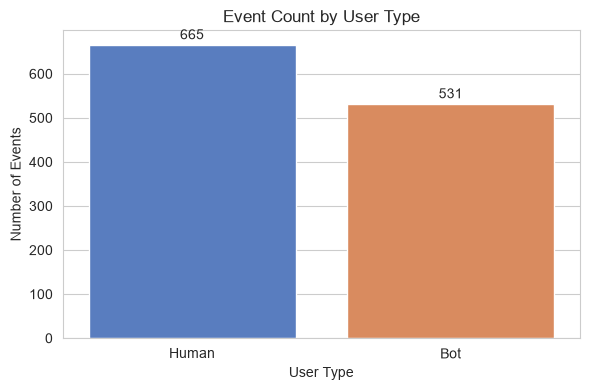

In [10]:
# 10. Human and Bot distribution
usertype_counts = df["UserType"].value_counts(dropna=False)
usertype_pct = (usertype_counts / len(df) * 100).round(2)
usertype_summary = pd.DataFrame({
    "count": usertype_counts,
    "percentage": usertype_pct
})
display(usertype_summary)
usertype_summary.to_csv(ANALYSIS_DIR / "usertype_distribution.csv")

# Visualisation: UserType distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=usertype_counts.index.astype(str), y=usertype_counts.values, ax=ax, palette="muted")
ax.set_xlabel("User Type")
ax.set_ylabel("Number of Events")
ax.set_title("Event Count by User Type")
for i, v in enumerate(usertype_counts.values):
    ax.text(i, v + max(usertype_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "usertype_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation:** The bar chart shows the number of events contributed by Human users versus Bots. A balanced or near-balanced split is desirable for unbiased bot-detection evaluation; a strong skew would mean the dataset is dominated by one class.

## 11. Analyse BotType distribution

For bot sessions, `BotType` further categorises the kind of bot (e.g., coordinated, simple). This distribution is examined only among bot records.

,count,percentage
BotType,,
NaN,665,55.60
CoordinatedBot,325,27.17
RandomBot,139,11.62
MimicBot,67,5.60


C:\Users\kavin\AppData\Local\Temp\ipykernel_22020\3320981955.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bottype_counts.index.astype(str), y=bottype_counts.values, ax=ax, palette="muted")


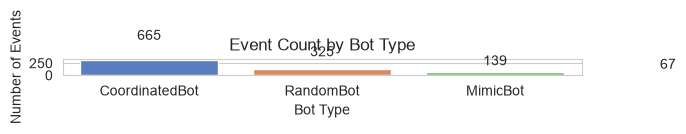

In [11]:
# 11. BotType distribution
bottype_counts = df["BotType"].value_counts(dropna=False)
bottype_pct = (bottype_counts / len(df) * 100).round(2)
bottype_summary = pd.DataFrame({
    "count": bottype_counts,
    "percentage": bottype_pct
})
display(bottype_summary)
bottype_summary.to_csv(ANALYSIS_DIR / "bottype_distribution.csv")

# Visualisation: BotType distribution
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=bottype_counts.index.astype(str), y=bottype_counts.values, ax=ax, palette="muted")
ax.set_xlabel("Bot Type")
ax.set_ylabel("Number of Events")
ax.set_title("Event Count by Bot Type")
for i, v in enumerate(bottype_counts.values):
    ax.text(i, v + max(bottype_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "bottype_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation:** This shows how bot events are split across bot subtypes. It helps determine whether coordinated bots form a meaningful subgroup for coordinated-activity analysis.

## 12. Analyse EventType distribution

`EventType` describes the kind of interaction recorded (e.g., click, mousemove, keypress). Understanding the mix of event types is important because different behaviours generate different feature sets.

,count,percentage
EventType,,
keypress,460,38.46
mousemove,393,32.86
click,109,9.11
field_interaction,104,8.70
scroll,82,6.86
session_start,26,2.17
form_submit,14,1.17
session_end,8,0.67


C:\Users\kavin\AppData\Local\Temp\ipykernel_22020\3478317109.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eventtype_counts.index.astype(str), y=eventtype_counts.values, ax=ax, palette="muted")


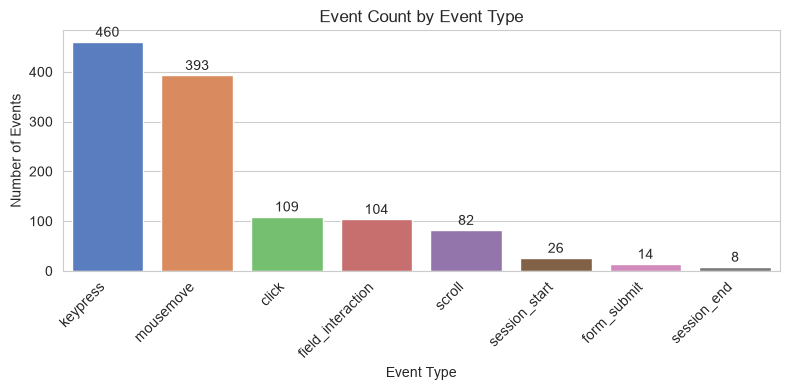

In [12]:
# 12. EventType distribution
eventtype_counts = df["EventType"].value_counts(dropna=False)
eventtype_pct = (eventtype_counts / len(df) * 100).round(2)
eventtype_summary = pd.DataFrame({
    "count": eventtype_counts,
    "percentage": eventtype_pct
})
display(eventtype_summary)
eventtype_summary.to_csv(ANALYSIS_DIR / "eventtype_distribution.csv")

# Visualisation: EventType distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=eventtype_counts.index.astype(str), y=eventtype_counts.values, ax=ax, palette="muted")
ax.set_xlabel("Event Type")
ax.set_ylabel("Number of Events")
ax.set_title("Event Count by Event Type")
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(eventtype_counts.values):
    ax.text(i, v + max(eventtype_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eventtype_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation:** The distribution reveals which interaction types dominate the dataset. Event types with very few records may produce unreliable feature estimates and should be treated carefully during fingerprinting.

## 13. Analyse SessionSource distribution

`SessionSource` indicates how a session was initiated (e.g., manual, research participant). This helps understand whether data collection conditions vary across sessions.

,count,percentage
SessionSource,,
Manual,540,45.15
Selenium,531,44.40
Research participant,124,10.37
NaN,1,0.08


C:\Users\kavin\AppData\Local\Temp\ipykernel_22020\746974134.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sessionsource_counts.index.astype(str), y=sessionsource_counts.values, ax=ax, palette="muted")


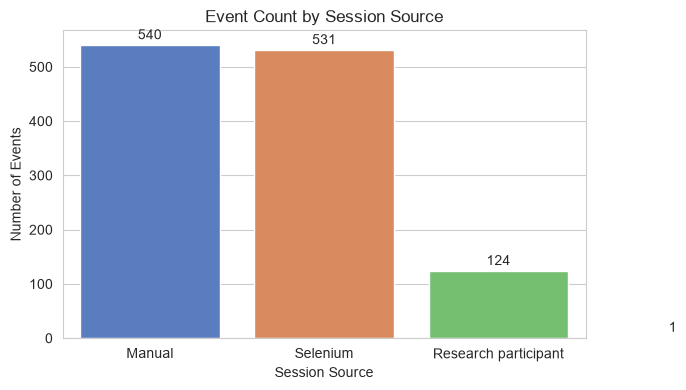

In [13]:
# 13. SessionSource distribution
sessionsource_counts = df["SessionSource"].value_counts(dropna=False)
sessionsource_pct = (sessionsource_counts / len(df) * 100).round(2)
sessionsource_summary = pd.DataFrame({
    "count": sessionsource_counts,
    "percentage": sessionsource_pct
})
display(sessionsource_summary)
sessionsource_summary.to_csv(ANALYSIS_DIR / "sessionsource_distribution.csv")

# Visualisation: SessionSource distribution
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=sessionsource_counts.index.astype(str), y=sessionsource_counts.values, ax=ax, palette="muted")
ax.set_xlabel("Session Source")
ax.set_ylabel("Number of Events")
ax.set_title("Event Count by Session Source")
for i, v in enumerate(sessionsource_counts.values):
    ax.text(i, v + max(sessionsource_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sessionsource_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation:** This shows whether sessions come from a single source or multiple sources. Multiple sources may introduce collection-condition variation that should be accounted for during analysis.

## 14. Calculate missing values and percentages

Missing values are quantified per column. In this event-level dataset, many nulls are structural (e.g., mouse coordinates are null on keyboard events), so they are reported rather than automatically filled.

,column_name,missing_count,missing_percentage
34,Detail,1196,100.00
31,TotalTypingEvents,1188,99.33
29,TotalClicks,1188,99.33
32,TotalNavigations,1188,99.33
30,TotalScrolls,1188,99.33
26,NavigationCount,1182,98.83
17,ClickIntervalMs,1119,93.56
19,ScrollDelta,1114,93.14
20,ScrollSpeed,1114,93.14
21,ScrollCount,1114,93.14


C:\Users\kavin\AppData\Local\Temp\ipykernel_22020\2567269017.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_plot["column_name"], y=missing_plot["missing_count"], ax=ax, palette="muted")


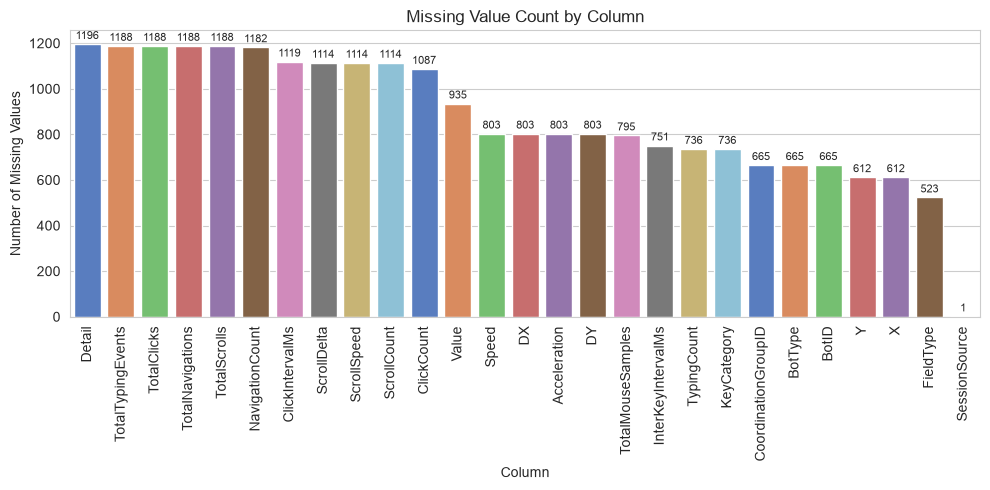

In [14]:
# 14. Missing values and percentages
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    "column_name": missing_counts.index,
    "missing_count": missing_counts.values,
    "missing_percentage": missing_pct.values
}).sort_values("missing_count", ascending=False)
display(missing_summary)
missing_summary.to_csv(ANALYSIS_DIR / "missing_values.csv", index=False)

# Visualisation: Missing value distribution
missing_plot = missing_summary[missing_summary["missing_count"] > 0]
if len(missing_plot) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(x=missing_plot["column_name"], y=missing_plot["missing_count"], ax=ax, palette="muted")
    ax.set_xlabel("Column")
    ax.set_ylabel("Number of Missing Values")
    ax.set_title("Missing Value Count by Column")
    plt.xticks(rotation=90)
    for i, v in enumerate(missing_plot["missing_count"].values):
        ax.text(i, v + max(missing_plot["missing_count"].values) * 0.01, str(v), ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "missing_values.png", bbox_inches="tight")
    plt.show()
else:
    print("No missing values found.")

**Interpretation:** Columns with high missing rates are typically event-type-specific fields (e.g., `X`/`Y` are null on non-mouse events). These are structural by design and should not be filled with zero; they will be handled appropriately during feature extraction per event type.

## 15. Identify duplicate records

Checking for fully duplicated rows, which could indicate data-entry errors or accidental replication.

In [15]:
# 15. Duplicate records
n_duplicates = int(df.duplicated().sum())
print(f"Number of fully duplicated rows: {n_duplicates}")
if n_duplicates > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(20))
else:
    print("No fully duplicated rows found.")

dup_summary = pd.DataFrame({
    "metric": ["duplicate_rows"],
    "value": [n_duplicates]
})
dup_summary.to_csv(ANALYSIS_DIR / "duplicate_records.csv", index=False)

Number of fully duplicated rows: 0
No fully duplicated rows found.


## 16. Analyse timestamp formats

Inspecting the `Timestamp` column to confirm its format and range. Timestamps are expected to be in epoch milliseconds.

In [16]:
# 16. Timestamp formats
ts = df["Timestamp"]
print(f"Timestamp dtype: {ts.dtype}")
print(f"Non-null timestamps: {ts.notna().sum()} / {len(ts)}")
print(f"Minimum timestamp: {ts.min()}")
print(f"Maximum timestamp: {ts.max()}")

ts_datetime = pd.to_datetime(ts, unit="ms", errors="coerce")
print(f"\nParsed minimum datetime: {ts_datetime.min()}")
print(f"Parsed maximum datetime: {ts_datetime.max()}")
print(f"Failed to parse: {ts_datetime.isna().sum()}")

ts_summary = pd.DataFrame({
    "metric": [
        "dtype",
        "non_null_count",
        "min_epoch_ms",
        "max_epoch_ms",
        "min_datetime",
        "max_datetime",
        "failed_to_parse"
    ],
    "value": [
        str(ts.dtype),
        int(ts.notna().sum()),
        int(ts.min()),
        int(ts.max()),
        str(ts_datetime.min()),
        str(ts_datetime.max()),
        int(ts_datetime.isna().sum())
]
})
ts_summary.to_csv(ANALYSIS_DIR / "timestamp_info.csv", index=False)

Timestamp dtype: int64
Non-null timestamps: 1196 / 1196
Minimum timestamp: 1792518973669
Maximum timestamp: 1794134163621

Parsed minimum datetime: 2026-10-20 17:56:13.669000
Parsed maximum datetime: 2026-11-08 10:36:03.621000
Failed to parse: 0


## 17. Check session-level record counts

Aggregating events per session to understand session density and identify sessions with unusually few or many events.

Events per session (summary statistics):


,events_per_session
count,24.000000
mean,49.833333
std,62.902731
min,1.000000
25%,11.750000
50%,18.500000
75%,70.000000
max,281.000000



Sessions with the most events:


SessionID
S-417ba60d-170d-4eae-a634-3c2ede814fb9    281
S-4fe30c98-b2c8-474a-b13d-68006c970e45    124
S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8    118
S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca    117
S-eb55632d-161a-4d81-bc4b-f1cad4b443ad     72
S-d1428074-91f3-4e18-a03f-19c2ac5f0996     70
S-af29303b-72ae-48cc-8a7b-a72a67179dca     70
S-bb8cb1a0-4659-41c6-8f7d-aabb1c8db493     64
S-b8b66e60-2612-47a9-93b7-5c35ed6d37ea     63
S-1710524c-4560-4abd-906c-6f336edff5de     56
dtype: int64


Sessions with the fewest events:


SessionID
S-d6ec1da5-583e-474b-a28e-ce022bd98187    16
S-e91eb227-b525-4476-a8dd-105073990fbb    14
S-63f13abe-3a3e-4932-a4fe-a7cddcb7ea76    13
S-1f44b887-5413-4283-91dc-5ac39b63feff    12
S-ff7069d1-3b65-4399-aed6-139f892bf782    11
S-7df9b2e8-ab6d-4887-bcf5-fa7287013afb    10
hjhjuhjhjhj                                4
ggfhg                                      3
gg                                         1
hjhjuhj                                    1
dtype: int64

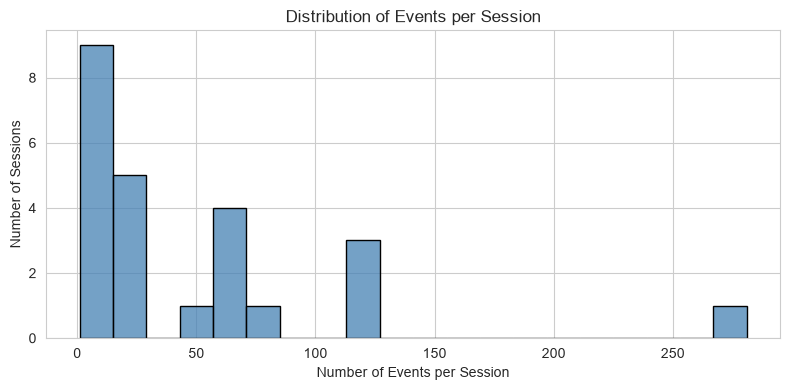

In [17]:
# 17. Session-level record counts
session_event_counts = df.groupby("SessionID").size().sort_values(ascending=False)
session_stats = session_event_counts.describe()
print("Events per session (summary statistics):")
display(session_stats.to_frame("events_per_session"))
print(f"\nSessions with the most events:")
display(session_event_counts.head(10))
print(f"\nSessions with the fewest events:")
display(session_event_counts.tail(10))

session_stats.to_csv(ANALYSIS_DIR / "session_record_counts.csv")
session_event_counts.to_csv(ANALYSIS_DIR / "session_event_counts.csv")

# Visualisation: Events per session
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(session_event_counts.values, bins=20, ax=ax, color="steelblue", edgecolor="black")
ax.set_xlabel("Number of Events per Session")
ax.set_ylabel("Number of Sessions")
ax.set_title("Distribution of Events per Session")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "events_per_session.png", bbox_inches="tight")
plt.show()

**Interpretation:** Sessions with very few events may not provide enough behaviour for reliable fingerprinting, while sessions with many events dominate the dataset. This spread informs how sessions are grouped and weighted in later stages.

## Dataset Overview and Issues Requiring Investigation

### Overview
- **Source file:** `dataset/raw/BotPrint_Research_Dataset.xlsx` (sheet: `Events`)
- **Total events:** 1196
- **Total columns:** 35
- **Unique sessions:** 24
- **User types:** Human and Bot (ground-truth `UserType` label present)
- **Bot subtypes:** present in `BotType` for bot sessions
- **Timestamp:** epoch milliseconds, parsable to datetime
- **Fully duplicated rows:** 0

### Issues requiring investigation

1. **Structural missing values:** Many columns (e.g., `X`, `Y`, `Speed`, `ClickIntervalMs`, `InterKeyIntervalMs`) have high missing rates because they only apply to specific event types. These must not be filled with zero; they should be handled per event type during feature extraction.
2. **Sparse aggregate columns:** `TotalMouseSamples`, `TotalClicks`, `TotalScrolls`, `TotalTypingEvents`, `TotalNavigations`, and `NavigationCount` are mostly null, suggesting they are only populated on certain session-level or summary events.
3. **`Detail` column is entirely null:** The `Detail` column contains no values and may be redundant.
4. **`Page` is constant:** All records have `Page` = "/", so it provides no discriminative information.
5. **`SessionSource` has one missing value:** A single null entry should be reviewed.
6. **Session size imbalance:** Sessions vary widely in event count; small sessions may not yield reliable behavioural fingerprints.

No preprocessing, imputation, or modelling is performed in this notebook. These issues will be addressed in the validation and preprocessing stages.